# Example 02: A Fourier spectrum compatible with a response spectrum

A response spectrum does not have a unique Fourier amplitude spectrum, but random vibration theory gives the Fourier spectrum whose response spectrum matches the target. `CompatibleRvtMotion` computes it for a target spectrum, a duration and a peak calculator. This example finds the compatible spectrum for one event with several peak calculators, and checks that each matches the target.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

import pyrvt

%matplotlib inline

## Target

`pyrvt.tools.read_events` reads the events of a spreadsheet or CSV file. Each has a response spectrum (`psa`), a duration, and the magnitude (`mag`), distance (`dist`) and region that some peak calculators need.

In [2]:
ext, periods, events = pyrvt.tools.read_events(Path("example_targetSa.csv"), "psa")
event = events[0]
target_freqs = 1.0 / periods
osc_damping = 0.05
calc_kwds = {key: event[key] for key in ["mag", "dist", "region"]}
print(
    {key: event[key] for key in ["mag", "dist", "region", "duration", "vs30", "kappa"]}
)

{'mag': 5, 'dist': 10, 'region': 'wna', 'duration': 5, 'vs30': 1000, 'kappa': '-'}


## Compatible motions

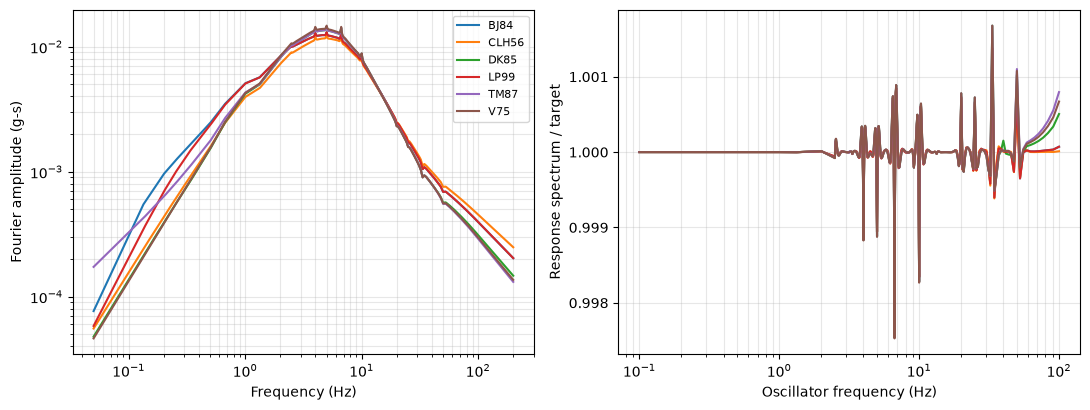

In [3]:
names = ["BJ84", "CLH56", "DK85", "LP99", "TM87", "V75"]
motions = {}
for name in names:
    motions[name] = pyrvt.motions.CompatibleRvtMotion(
        target_freqs,
        event["psa"],
        duration=event["duration"],
        osc_damping=osc_damping,
        peak_calculator=name,
        calc_kwds=calc_kwds,
    )

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name, m in motions.items():
    axes[0].plot(m.freqs, m.fourier_amps, label=name)
    axes[1].plot(
        target_freqs,
        m.calc_osc_accels(target_freqs, osc_damping) / event["psa"],
        label=name,
    )
axes[0].set(
    xscale="log",
    yscale="log",
    xlabel="Frequency (Hz)",
    ylabel="Fourier amplitude (g-s)",
)
axes[1].set(
    xscale="log",
    xlabel="Oscillator frequency (Hz)",
    ylabel="Response spectrum / target",
)
for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=8)
fig.tight_layout()

## Attenuation

The decay of the compatible Fourier spectrum above a frequency gives the site attenuation $\kappa$ that the spectrum implies. `calc_attenuation` fits it above 30 Hz.

In [4]:
for name, m in motions.items():
    kappa, *_ = m.calc_attenuation(30.0)
    print(f"{name:6s} kappa = {kappa:.4f} s   PGA = {m.pga:.3f} g")

BJ84   kappa = 0.0033 s   PGA = 0.076 g
CLH56  kappa = 0.0030 s   PGA = 0.073 g
DK85   kappa = 0.0037 s   PGA = 0.078 g
LP99   kappa = 0.0033 s   PGA = 0.076 g
TM87   kappa = 0.0039 s   PGA = 0.078 g
V75    kappa = 0.0038 s   PGA = 0.078 g


### Observations

- **Every compatible motion matches the target**: the response spectrum of each is within 0.3% of the target at all of the oscillator frequencies, so the choice of the peak calculator changes the Fourier spectrum and not the response spectrum.
- **The Fourier spectra are close from 1 to 20 Hz** and differ outside of that range. Below 0.3 Hz Toro and McGuire (1987) is several times larger than Vanmarcke (1975) at 0.05 Hz, and above 30 Hz Cartwright and Longuet-Higgins (1956) and Liu and Pezeshk (1999) decay more slowly than the others.
- **The implied attenuation** above 30 Hz is 0.0030 s for Cartwright and Longuet-Higgins (1956) to 0.0039 s for Toro and McGuire (1987), and the PGA is 0.073 to 0.078 g.